# 설정값 민감도 검증 (5개 항목)

`김희서/분석_설정값_및_검증항목.md`에서 추린 5개 항목만 실제 데이터로 확인한다.

- 목적: **최적값 찾기가 아니라**, 현재 결과가 특정 설정값에 과도하게 의존하는지 확인
- 기존 코드·데이터·문서는 읽기만 한다. 이 notebook은 파일을 쓰지 않는다.
- 시나리오 A~D가 잘 잡히도록 기준을 맞추지 않는다. 결과가 사라지면 그대로 적는다.
- 경보가 아닌 세션은 `비경보/정상 후보`라고 부른다 (정상으로 확정한 것이 아님).

# 0. 환경 및 데이터 로드

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "README.md").exists())
DATA = ROOT / "data"

_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ["Malgun Gothic", "NanumGothic", "AppleGothic"] if f in _fonts), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)


def read(rel, **kw):
    return pd.read_csv(DATA / rel, encoding="utf-8-sig", **kw)


def ts(s):
    return pd.to_datetime(s, format="mixed")


# 세션 테이블 (146행)
sessions = read("07_sessions/sessions.csv", usecols=[
    "work_session_id", "session_type", "person_candidate", "client_ip", "client_zone", "start_utc", "end_utc",
    "ssh_end_utc", "start_hour_kst", "duration_min", "ssh_connections", "hosts", "process_count", "non_get_count"])
for c in ["start_utc", "end_utc", "ssh_end_utc"]:
    sessions[c] = ts(sessions[c])

# 기준선 비교값 (현행 결과, 재현 확인용)
sb = read("08_baseline/session_baseline.csv", usecols=[
    "work_session_id", "baseline_level", "baseline_n", "hist_hour_min", "hist_hour_max", "hour_distance",
    "process_count_above_max", "non_get_count_above_max"])

det = read("09_detections/detections.csv")
det["t"] = ts(det["event_time_utc"])
risk = read("10_risk/session_risk.csv", usecols=["work_session_id", "risk_score", "alert"])
risk_events = read("10_risk/risk_events.csv", usecols=["detection_type", "work_session_id", "link", "signal_score"])
ext_profile = read("08_baseline/external_profile.csv")

# peer 그룹(home_host) 재현에만 쓰는 작은 보강 테이블 (23행)
accounts = read("05_enriched/account_inventory.csv", usecols=["account_system", "account_type", "person_candidate", "home_host"])

# 타임라인은 1·2번에 필요한 컬럼만 읽는다
tl = read("07_sessions/timeline_sessions.csv", dtype=str, usecols=[
    "event_time_utc", "log_source", "event_action", "client_ip", "client_zone", "account", "account_type",
    "host", "bucket", "work_session_id", "Image", "CommandLine", "ParentUser", "ProcessGuid", "ParentProcessGuid",
    "dst", "dpt", "unmapped"])
tl["t"] = ts(tl["event_time_utc"])

ALERT = set(risk.loc[risk["alert"].astype(str).str.lower() == "true", "work_session_id"])
print("프로젝트 루트:", ROOT.name)
print(f"세션 {len(sessions)} / 탐지 신호 {len(det)} / 타임라인 {len(tl)}행")
print("경보 세션:", sorted(ALERT))

프로젝트 루트: security-log-cross-analysis
세션 146 / 탐지 신호 76 / 타임라인 9125행
경보 세션: ['S122', 'S132', 'S137', 'S142']


# 1. 시스템 탐지 사용자 귀속 검증

**현재 기준** — 세션 없는 시스템 탐지(root·www-data)를 "같은 서버 + SSH 세션 시간 안"의 사용자 세션에 연결한다.
여기서 "같은 서버"는 세션이 실제로 프로세스를 실행한 서버(`hosts`) **또는** 그 사람의 추정 주 작업 서버(`home_host`)다.

**검증 방법** — 민감도 분석이 아니라 귀속 타당성 확인이다.
① S137에 연결된 신호 목록, ② 같은 시각 후보 세션 수, ③ 시간 차이, ④ 직접 귀속 근거(auditd·sudo·실행 사용자 ID)의 존재 여부를 본다.

In [2]:
SID = "S137"
home = {r.person_candidate: r.home_host for r in accounts.itertuples()
        if r.account_system == "linux" and r.account_type == "human"}


def host_set(v):
    return {h.split(":")[0] for h in str(v).split("|") if h and h != "nan"}


srv = sessions[sessions["ssh_end_utc"].notna()].copy()
srv["observed_hosts"] = srv["hosts"].map(host_set)                       # 실제로 프로세스를 실행한 서버 (관측)
srv["home_host"] = srv["person_candidate"].map(home)                     # 추정 주 작업 서버

sys_det = det[det["work_session_id"].isna() & det["host"].notna()].copy()  # 세션 없는 시스템 탐지 전체
rows = []
for d in sys_det.itertuples():
    live = srv[(srv["start_utc"] <= d.t) & (d.t <= srv["ssh_end_utc"])]
    by_rule = live[np.array([d.host in o or d.host == h for o, h in zip(live["observed_hosts"], live["home_host"])], dtype=bool)]
    by_obs = live[np.array([d.host in o for o in live["observed_hosts"]], dtype=bool)]
    rows.append({
        "detection_id": d.detection_id, "탐지 ID": d.detection_type, "심각도": d.severity if isinstance(d.severity, str) else "(행위)",
        "host": d.host, "계정": d.account, "event_time_utc": d.t, "linked_session": d.linked_sessions,
        "현행 규칙 후보 수": len(by_rule), "후보": "|".join(by_rule["work_session_id"]),
        "그 서버 프로세스 관측 후보 수": len(by_obs),
        "같은 시각 SSH 접속 중인 전체 세션 수": len(live),
    })
sys_tbl = pd.DataFrame(rows)
print(f"세션 없는 시스템 탐지 {len(sys_tbl)}건 (서버별: {sys_tbl['host'].value_counts().to_dict()})")
print("서버·시간 규칙의 후보 수 분포 (web-01 8건은 웹 요청 규칙으로 S132에 연결되며 이번 검증 대상이 아님):",
      sys_tbl.groupby("host")["현행 규칙 후보 수"].value_counts().to_dict())

s137 = sessions.set_index("work_session_id").loc[SID]
t1 = sys_tbl[sys_tbl["linked_session"].str.startswith(SID)].copy()
t1["연결 방식"] = np.where(t1["그 서버 프로세스 관측 후보 수"] > 0, "서버·시간 (hosts 관측)", "서버·시간 (home_host 추정)")
t1["SSH 시작 후(초)"] = (t1["event_time_utc"] - s137["start_utc"]).dt.total_seconds().round().astype(int)
t1["SSH 종료까지(분)"] = ((s137["ssh_end_utc"] - t1["event_time_utc"]).dt.total_seconds() / 60).round(1)
t1["linked_session"] = SID
display(t1[["detection_id", "탐지 ID", "심각도", "host", "계정", "event_time_utc", "linked_session", "연결 방식",
            "SSH 시작 후(초)", "SSH 종료까지(분)", "현행 규칙 후보 수", "그 서버 프로세스 관측 후보 수",
            "같은 시각 SSH 접속 중인 전체 세션 수"]].reset_index(drop=True))

세션 없는 시스템 탐지 20건 (서버별: {'node-01': 12, 'web-01': 8})
서버·시간 규칙의 후보 수 분포 (web-01 8건은 웹 요청 규칙으로 S132에 연결되며 이번 검증 대상이 아님): {('node-01', 1): 12, ('web-01', 0): 8}


,detection_id,탐지 ID,심각도,host,계정,event_time_utc,linked_session,연결 방식,SSH 시작 후(초),SSH 종료까지(분),현행 규칙 후보 수,그 서버 프로세스 관측 후보 수,같은 시각 SSH 접속 중인 전체 세션 수
0,D0057,B09,(행위),node-01,root,2026-10-15 17:41:29.440,S137,서버·시간 (home_host 추정),20,39.7,1,0,1
1,D0058,R02,high,node-01,root,2026-10-15 17:41:29.440,S137,서버·시간 (home_host 추정),20,39.7,1,0,1
2,D0059,B09,(행위),node-01,root,2026-10-15 17:41:31.440,S137,서버·시간 (home_host 추정),22,39.6,1,0,1
3,D0060,B09,(행위),node-01,root,2026-10-15 17:41:32.440,S137,서버·시간 (home_host 추정),23,39.6,1,0,1
4,D0061,B09,(행위),node-01,root,2026-10-15 17:41:32.440,S137,서버·시간 (home_host 추정),23,39.6,1,0,1
5,D0062,R03,medium,node-01,root,2026-10-15 17:41:32.440,S137,서버·시간 (home_host 추정),23,39.6,1,0,1
6,D0063,R06,medium,node-01,root,2026-10-15 17:41:32.440,S137,서버·시간 (home_host 추정),23,39.6,1,0,1
7,D0064,B09,(행위),node-01,root,2026-10-15 17:42:29.440,S137,서버·시간 (home_host 추정),80,38.7,1,0,1
8,D0065,R05,high,node-01,root,2026-10-15 17:42:43.440,S137,서버·시간 (home_host 추정),94,38.4,1,0,1
9,D0066,B09,(행위),node-01,root,2026-10-15 17:42:50.440,S137,서버·시간 (home_host 추정),101,38.3,1,0,1


In [3]:
# 후보가 1명뿐이었던 이유: 그 시각 전후로 다른 세션이 얼마나 떨어져 있었나
first_t, last_t = t1["event_time_utc"].min(), t1["event_time_utc"].max()
others = sessions[sessions["work_session_id"] != SID]
before = others[others["end_utc"] < first_t].sort_values("end_utc").iloc[-1]
after = others[others["start_utc"] > last_t].sort_values("start_utc").iloc[0]
peer_p = [p for p, h in home.items() if h == "node-01" and p != s137["person_candidate"]]
peer_s = others[others["person_candidate"].isin(peer_p)]
pb = peer_s[peer_s["end_utc"] < first_t].sort_values("end_utc").iloc[-1]
pa = peer_s[peer_s["start_utc"] > last_t].sort_values("start_utc").iloc[0]
ctx = pd.DataFrame([
    {"구분": "직전 세션 (전체)", "세션": before.work_session_id, "사람 후보": before.person_candidate,
     "탐지 구간과의 간격(시간)": round((first_t - before.end_utc).total_seconds() / 3600, 1)},
    {"구분": "직후 세션 (전체)", "세션": after.work_session_id, "사람 후보": after.person_candidate,
     "탐지 구간과의 간격(시간)": round((after.start_utc - last_t).total_seconds() / 3600, 1)},
    {"구분": "직전 세션 (node-01 동료)", "세션": pb.work_session_id, "사람 후보": pb.person_candidate,
     "탐지 구간과의 간격(시간)": round((first_t - pb.end_utc).total_seconds() / 3600, 1)},
    {"구분": "직후 세션 (node-01 동료)", "세션": pa.work_session_id, "사람 후보": pa.person_candidate,
     "탐지 구간과의 간격(시간)": round((pa.start_utc - last_t).total_seconds() / 3600, 1)},
])
display(ctx)

# S137 자체가 node-01에 있었다는 관측이 있는가
own = sessions[sessions["person_candidate"] == s137["person_candidate"]]
print(f"{SID} 세션의 hosts: {s137['hosts']!r}, process_count: {s137['process_count']}")
print(f"{s137['person_candidate']} 전체 {len(own)}세션 중 node-01 프로세스가 관측된 세션: "
      f"{int(own['hosts'].map(lambda v: 'node-01' in host_set(v)).sum())}")
print("S137 sshd 이벤트가 기록된 서버:", tl[(tl.work_session_id == SID) & (tl.log_source == "sshd")]["host"].unique().tolist())

,구분,세션,사람 후보,탐지 구간과의 간격(시간)
0,직전 세션 (전체),S136,web01,8.1
1,직후 세션 (전체),S138,admin01,7.0
2,직전 세션 (node-01 동료),S131,ops01,13.2
3,직후 세션 (node-01 동료),S139,ops01,8.1


S137 세션의 hosts: nan, process_count: 0
ops02 전체 17세션 중 node-01 프로세스가 관측된 세션: 16
S137 sshd 이벤트가 기록된 서버: ['bastion-01']


In [4]:
# 직접 귀속 근거가 현재 데이터에 있는가
root_ev = tl[(tl.host == "node-01") & (tl.account == "root") & (tl.t >= first_t) & (tl.t <= last_t)]
root_pc = root_ev[root_ev.event_action == "process_create"]
all_pc = tl[(tl.log_source == "sysmon") & (tl.event_action == "process_create")].copy()
all_pc["LogonId"] = all_pc["unmapped"].map(lambda u: json.loads(u).get("LogonId") if isinstance(u, str) else None)
known_guid = set(all_pc["ProcessGuid"])
cmd = tl["CommandLine"].fillna("")
sudo_n = int(cmd.str.contains(r"(?:^|[\s/;|&'\"])(?:sudo|su)(?:\s|$)", regex=True).sum())

# 17:41:29에 생성된 root bash가 언제 끝났는지 (같은 ProcessGuid)
bash_guid = root_pc.sort_values("t").iloc[0]["ProcessGuid"]
bash_end = tl[(tl.ProcessGuid == bash_guid) & (tl.event_action == "process_terminate")]["t"]
bash_end = bash_end.iloc[0] if len(bash_end) else pd.NaT

evidence = pd.DataFrame([
    {"직접 귀속 근거": "auditd (auid = 로그인 사용자 ID)", "현재 데이터": "로그 소스: " + ", ".join(sorted(tl.log_source.unique())),
     "있음/없음": "없음"},
    {"직접 귀속 근거": "sudo / su 실행 기록", "현재 데이터": f"CommandLine에 sudo·su가 있는 이벤트 {sudo_n}건",
     "있음/없음": "없음" if sudo_n == 0 else "있음"},
    {"직접 귀속 근거": "node-01 로그인 기록 (sshd)", "현재 데이터": "sshd 기록 서버: " + ", ".join(sorted(tl[tl.log_source == 'sshd'].host.unique())),
     "있음/없음": "없음 (bastion-01만 수집)"},
    {"직접 귀속 근거": "root 이벤트의 ParentUser", "현재 데이터": "값: " + ", ".join(sorted(root_pc.ParentUser.dropna().unique())),
     "있음/없음": "사람 계정 아님"},
    {"직접 귀속 근거": "root 이벤트의 부모 프로세스 추적 (ParentProcessGuid)",
     "현재 데이터": f"부모 프로세스 생성 이벤트가 로그에 있는 경우 {int(root_pc.ParentProcessGuid.isin(known_guid).sum())} / {len(root_pc)}",
     "있음/없음": "추적 불가"},
    {"직접 귀속 근거": "Sysmon LogonId (실행 사용자 세션 ID)",
     "현재 데이터": f"root 전체 {sorted(all_pc[all_pc.account == 'root'].LogonId.unique())}, 사람 계정 전체 {sorted(all_pc[all_pc.account_type == 'human'].LogonId.unique())}",
     "있음/없음": "세션·사람 구분 불가"},
    {"직접 귀속 근거": f"{SID} 세션의 node-01 사람 계정 프로세스", "현재 데이터": f"{int(s137['process_count'])}건",
     "있음/없음": "없음"},
])
display(evidence)

# 연결을 빼면 점수가 어떻게 되나 (탐지 종류별 최고 1개 합산은 6단계 규칙 그대로)
re137 = risk_events[risk_events.work_session_id == SID].groupby(["link", "detection_type"])["signal_score"].max()
score_by_link = re137.groupby("link").sum()
print("S137 점수 구성:", score_by_link.to_dict(), "→ 합계", score_by_link.sum())
print("root bash 생성 → 종료:", root_pc.sort_values('t').iloc[0]['t'], "→", bash_end, "/ SSH 종료:", s137["ssh_end_utc"])

,직접 귀속 근거,현재 데이터,있음/없음
0,auditd (auid = 로그인 사용자 ID),"로그 소스: nginx, sshd, sysmon, teiren_audit",없음
1,sudo / su 실행 기록,CommandLine에 sudo·su가 있는 이벤트 0건,없음
2,node-01 로그인 기록 (sshd),sshd 기록 서버: bastion-01,없음 (bastion-01만 수집)
3,root 이벤트의 ParentUser,값: root,사람 계정 아님
4,root 이벤트의 부모 프로세스 추적 (ParentProcessGuid),부모 프로세스 생성 이벤트가 로그에 있는 경우 0 / 2,추적 불가
5,Sysmon LogonId (실행 사용자 세션 ID),"root 전체 ['0'], 사람 계정 전체 ['1001']",세션·사람 구분 불가
6,S137 세션의 node-01 사람 계정 프로세스,0건,없음


S137 점수 구성: {'direct': 40.0, 'linked': 208.0} → 합계 248.0
root bash 생성 → 종료: 2026-10-15 17:41:29.440000 → 2026-10-15 18:19:29.440000 / SSH 종료: 2026-10-15 18:21:09.448000


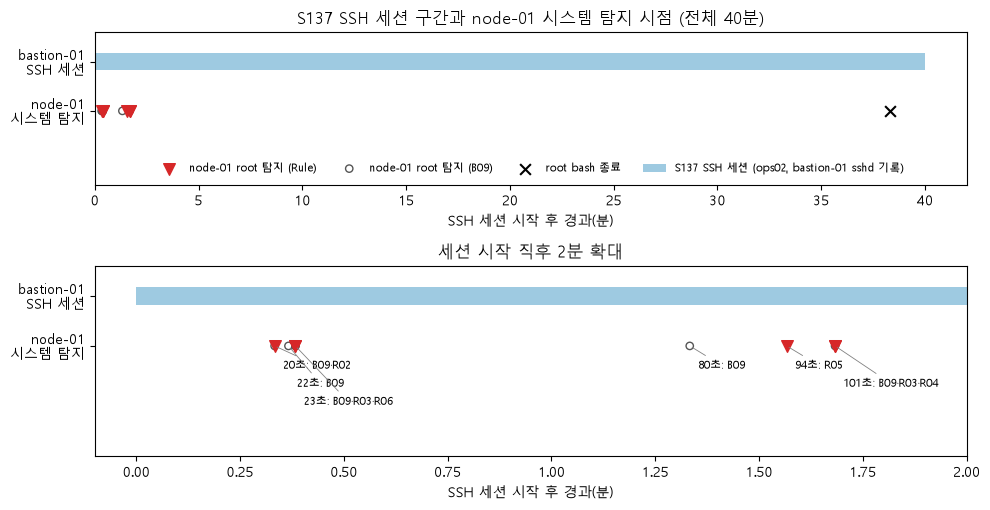

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.2), gridspec_kw={"height_ratios": [1, 1.25]})
is_rule = t1["탐지 ID"].str.startswith("R")
for ax in (ax1, ax2):
    ax.barh(1, (s137["ssh_end_utc"] - s137["start_utc"]).total_seconds() / 60, left=0, height=0.35,
            color="#9ecae1", label=f"{SID} SSH 세션 (ops02, bastion-01 sshd 기록)")
    m = (t1["event_time_utc"] - s137["start_utc"]).dt.total_seconds() / 60
    ax.scatter(m[is_rule], [0] * is_rule.sum(), marker="v", s=70, color="#d62728", label="node-01 root 탐지 (Rule)", zorder=3)
    ax.scatter(m[~is_rule], [0] * (~is_rule).sum(), marker="o", s=28, facecolors="none", edgecolors="#555555",
               label="node-01 root 탐지 (B09)", zorder=2)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["node-01\n시스템 탐지", "bastion-01\nSSH 세션"])
    ax.set_ylim(-0.7, 1.6)
if pd.notna(bash_end):
    ax1.scatter([(bash_end - s137["start_utc"]).total_seconds() / 60], [0], marker="x", s=60, color="black", label="root bash 종료")
ax1.set_title(f"{SID} SSH 세션 구간과 node-01 시스템 탐지 시점 (전체 40분)")
ax1.set_xlabel("SSH 세션 시작 후 경과(분)")
ax1.set_ylim(-1.5, 1.6)
ax1.legend(loc="lower center", fontsize=8, ncol=4, frameon=False)
ax2.set_xlim(-0.1, 2.0)
ax2.set_title("세션 시작 직후 2분 확대")
ax2.set_xlabel("SSH 세션 시작 후 경과(분)")
level, prev_x = 0, None
for tt, g in t1.groupby("event_time_utc"):                       # 가까운 시점의 라벨은 한 줄씩 내려 겹치지 않게 한다
    x = (tt - s137["start_utc"]).total_seconds() / 60
    level = level + 1 if prev_x is not None and x - prev_x < 0.15 else 0
    prev_x = x
    ax2.annotate(f"{int(round(x * 60))}초: " + "·".join(sorted(set(g["탐지 ID"]))), (x, 0), xytext=(6, -14 - 13 * level),
                 textcoords="offset points", ha="left", va="center", fontsize=8,
                 arrowprops={"arrowstyle": "-", "color": "gray", "lw": 0.6})
ax2.set_ylim(-2.2, 1.6)
plt.tight_layout()
plt.show()

**한 줄 결론** — node-01의 root 위험 활동과 같은 시각 ops02의 SSH 세션은 각각 관측되지만, 둘을 잇는 근거는 시간 겹침과 `home_host` 추정뿐이라 **실제 실행 주체는 현재 데이터로 확인할 수 없다.**

| 구분 | 내용 | 근거 수준 |
|---|---|---|
| 시스템 위험 활동 발생 | node-01에서 root가 다운로드 실행·숨김 파일·내부 22번 3대·외부 4444 연결 (탐지 12건, high Rule 3종) | 관측 |
| 해당 시각 ops02 세션 존재 | S137이 bastion-01 sshd에 17:41:09~18:21:09로 기록. 탐지는 세션 시작 20~101초 뒤 | 관측 |
| 후보가 1명 | 그 시각 SSH 접속 중인 세션은 전체에서 S137 하나. 다른 세션은 앞뒤로 7~8시간 떨어져 있음 | 관측 |
| ops02가 node-01에 있었음 | S137에는 node-01 사람 계정 프로세스가 0건. 연결은 `home_host = node-01`로만 성립 | 추정 |
| root 활동을 ops02에게 귀속 | 서버(추정)·시간만 근거 | 추정 |
| 실제 실행 주체 | auditd·sudo 기록·node-01 로그인 기록 없음, 부모 프로세스 추적 불가, LogonId로 구분 불가 | 확인 불가 |

- 후보가 여러 명이어서 모호한 것이 아니라, **후보가 1명인데 그 1명을 직접 잇는 키가 없는 것**이다.
- 연결(linked 208점)을 빼면 S137의 직접 점수는 40점이다.
- root bash는 SSH 세션 시작 20초 뒤 생기고 SSH 종료 100초 전에 끝났다. 시간상 맞물리지만 이것도 시간 근거일 뿐 귀속 증거는 아니다.

# 2. R09 시간창·횟수 민감도

**현재 기준** — 같은 IP에서 1시간 안에 로그인 실패 5회 이상 (현행 탐지 0건).

**검증 방법** — sshd 실패 이벤트(`invalid_user`, `auth_failure`)를 IP별·시간순으로 놓고 시간창 4개 × 최소 횟수 3개를 비교한다.

**집계 방식(중복 방지)** — IP별로 *겹치지 않는 창*을 쓴다.
아직 어느 창에도 쓰이지 않은 가장 이른 실패를 창 시작 `t0`로 두고 `[t0, t0+시간창]` 안의 실패 수가 기준 이상이면 **탐지 창 1개**로 기록한 뒤,
창이 끝난 다음의 첫 실패부터 다시 센다. 기준 미달이면 시작점을 다음 실패로 한 칸 옮긴다. 따라서 같은 실패 이벤트는 탐지 창 하나에만 들어간다.

In [6]:
FAIL = {"invalid_user", "auth_failure"}
fail = tl[(tl.log_source == "sshd") & tl.event_action.isin(FAIL)].sort_values("t")
print("현행 R09 탐지 건수 (detections.csv):", int((det.detection_type == "R09").sum()))

ip_tbl = fail.groupby("client_ip").agg(
    client_zone=("client_zone", "first"), 분류=("bucket", "first"), 실패_횟수=("t", "size"),
    첫_시도=("t", "min"), 마지막_시도=("t", "max"), 서로_다른_계정=("account", "nunique"))
ip_tbl["기간(일)"] = ((ip_tbl["마지막_시도"] - ip_tbl["첫_시도"]).dt.total_seconds() / 86400).round(1)
gaps = fail.groupby("client_ip")["t"].apply(lambda s: s.diff().dt.total_seconds().dropna() / 3600)
ip_tbl["시도 간격 최소(시간)"] = gaps.groupby(level=0).min().round(2)
ip_tbl["시도 간격 중앙값(시간)"] = gaps.groupby(level=0).median().round(1)
ip_tbl["분류"] = ip_tbl["분류"].map({"external": "세션 없는 외부 시도", "session": "세션에 연결된 IP (S122)"})
display(ip_tbl)

n_internal_fail = int((ip_tbl["client_zone"] != "external").sum())
print(f"실패 로그인이 1회라도 있는 내부/사용자 IP 수: {n_internal_fail} "
      f"(세션을 가진 내부 IP는 {sessions.loc[sessions.client_zone != 'external', 'client_ip'].nunique()}개)")

현행 R09 탐지 건수 (detections.csv): 0


,client_zone,분류,실패_횟수,첫_시도,마지막_시도,서로_다른_계정,기간(일),시도 간격 최소(시간),시도 간격 중앙값(시간)
client_ip,,,,,,,,,
165.154.235.9,external,세션 없는 외부 시도,46,2026-10-01 07:54:20.472320,2026-10-16 14:00:26.190837,5,15.3,0.02,6.8
203.0.113.44,external,세션에 연결된 IP (S122),3,2026-10-14 18:11:38.120000,2026-10-14 18:11:47.120000,1,0.0,0.00,0.0
213.176.26.69,external,세션 없는 외부 시도,49,2026-10-01 05:43:57.673783,2026-10-16 05:35:14.871536,5,15.0,0.13,6.0
45.148.10.151,external,세션 없는 외부 시도,66,2026-09-30 18:54:02.473850,2026-10-16 10:34:35.482629,5,15.7,0.07,4.5


실패 로그인이 1회라도 있는 내부/사용자 IP 수: 0 (세션을 가진 내부 IP는 8개)


In [7]:
WINDOWS = {"1시간": pd.Timedelta(hours=1), "6시간": pd.Timedelta(hours=6), "24시간": pd.Timedelta(hours=24), "7일": pd.Timedelta(days=7)}
COUNTS = [3, 5, 10]


def detect_windows(times, accts, window, n_min):
    """겹치지 않는 창으로 (창 시작, 실패 수, 서로 다른 계정 수)를 돌려준다."""
    out, i = [], 0
    while i < len(times):
        j = int(np.searchsorted(times, times[i] + window, side="right"))
        if j - i >= n_min:
            out.append((times[i], j - i, len(set(accts[i:j]))))
            i = j
        else:
            i += 1
    return out


per_ip = {ip: (g["t"].to_numpy(), g["account"].to_numpy()) for ip, g in fail.groupby("client_ip")}
zone = ip_tbl["client_zone"].to_dict()
SCAN_IPS = set(ip_tbl.index[ip_tbl["분류"] == "세션 없는 외부 시도"])

rows, win_rows = [], []
for wname, w in WINDOWS.items():
    for n_min in COUNTS:
        hits = {ip: detect_windows(t, a, w.to_timedelta64(), n_min) for ip, (t, a) in per_ip.items()}
        hits = {ip: h for ip, h in hits.items() if h}
        accts = [x[2] for h in hits.values() for x in h]
        rows.append({
            "시간창": wname, "최소 실패 횟수": n_min,
            "탐지 IP 수": len(hits),
            "외부 IP 수": sum(zone[ip] == "external" for ip in hits),
            "└ 세션 없는 외부 시도 IP (전체 3개)": len(SCAN_IPS & set(hits)),
            "└ 세션 연결 IP 203.0.113.44": int("203.0.113.44" in hits),
            "내부/사용자 IP 수": sum(zone[ip] != "external" for ip in hits),
            "총 탐지 창 수": sum(len(h) for h in hits.values()),
            "창당 서로 다른 계정 수 (중앙값)": float(np.median(accts)) if accts else np.nan,
            "창당 서로 다른 계정 수 (최대)": max(accts) if accts else np.nan,
        })
r09_grid = pd.DataFrame(rows)
display(r09_grid)

# 참고: IP별로 어떤 창에서든 관측된 최대 실패 수 (창 시작을 모든 실패 시각으로 옮겨 본 최댓값)
mx = {ip: {wname: max(int(np.searchsorted(t, x + w.to_timedelta64(), side="right")) - i for i, x in enumerate(t))
           for wname, w in WINDOWS.items()} for ip, (t, a) in per_ip.items()}
r09_max = pd.DataFrame(mx).T
r09_max.columns = [f"{c} 안 최대 실패 수" for c in r09_max.columns]
display(r09_max)

,시간창,최소 실패 횟수,탐지 IP 수,외부 IP 수,└ 세션 없는 외부 시도 IP (전체 3개),└ 세션 연결 IP 203.0.113.44,내부/사용자 IP 수,총 탐지 창 수,창당 서로 다른 계정 수 (중앙값),창당 서로 다른 계정 수 (최대)
0,1시간,3,2,2,1,1,0,2,2.0,3.0
1,1시간,5,0,0,0,0,0,0,NaN,NaN
2,1시간,10,0,0,0,0,0,0,NaN,NaN
3,6시간,3,4,4,3,1,0,19,3.0,4.0
4,6시간,5,1,1,1,0,0,1,4.0,4.0
5,6시간,10,0,0,0,0,0,0,NaN,NaN
6,24시간,3,4,4,3,1,0,36,3.0,5.0
7,24시간,5,3,3,3,0,0,20,4.0,5.0
8,24시간,10,0,0,0,0,0,0,NaN,NaN
9,7일,3,4,4,3,1,0,9,5.0,5.0


,1시간 안 최대 실패 수,6시간 안 최대 실패 수,24시간 안 최대 실패 수,7일 안 최대 실패 수
165.154.235.9,3,4,7,25
203.0.113.44,3,3,3,3
213.176.26.69,2,5,8,29
45.148.10.151,2,4,8,34


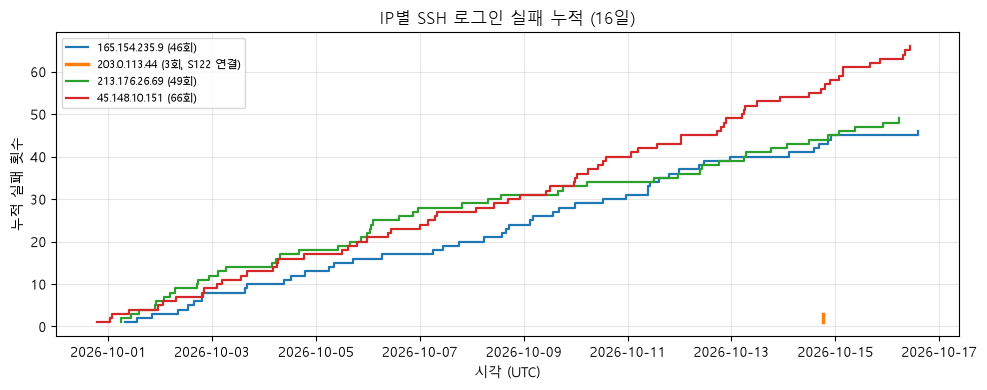

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
for ip, (t, a) in per_ip.items():
    label = f"{ip} ({len(t)}회" + (", S122 연결)" if ip not in SCAN_IPS else ")")
    ax.step(t, np.arange(1, len(t) + 1), where="post", label=label, linewidth=1.6 if ip in SCAN_IPS else 2.5)
ax.set_title("IP별 SSH 로그인 실패 누적 (16일)")
ax.set_xlabel("시각 (UTC)")
ax.set_ylabel("누적 실패 횟수")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**한 줄 결론** — 현행 1시간/5회는 세션 없는 외부 시도 IP 3개(각 46~66회, 15~16일)를 하나도 잡지 못하고, 창을 24시간 이상으로 늘려야 3개가 모두 잡힌다. 내부/사용자 IP는 어느 조합에서도 추가 탐지되지 않았다.

- 1시간 안 최대 실패 수는 IP별 2~3회라 5회 기준에 닿지 않는다. 24시간/5회는 3개 IP·창 20개, 7일/10회는 3개 IP·창 6개다. 24시간/10회는 0건이다(24시간 최대 7~8회).
- 최소 3회로 낮추면 203.0.113.44(S122 직전 실패 3회)도 잡히는데, 이 건은 이미 R10으로 탐지된 것이다.
- **주의:** 내부/사용자 IP는 실패 로그인이 원래 0건이다. 그래서 "정상 IP가 같이 얼마나 늘어나는가"는 이 데이터로 측정되지 않는다. 0은 오탐이 없다는 증거가 아니다.

# 3. B01 시작 시각 민감도

**현재 기준** — 개인(또는 peer) **과거** 세션 시작 시각(KST)의 최소~최대 범위에서 2시간 이상 벗어나면 B01.
2시간은 비교 가능 세션 중 5% 이하가 되는 첫 경계다.

**검증 방법** — 과거 세션만 쓰는 조건(세션 시작 전에 끝난 세션)은 그대로 두고 세 방법을 같은 세션에 적용한다.

- A. 현행: 과거 min~max, 이탈 ≥ 2시간
- B. 과거 min~max, 이탈 ≥ 3시간
- C. 과거 5~95% 분위수 범위, 이탈 ≥ 2시간. 과거 세션이 10개 미만이면 계산하지 않고 `표본 부족`으로 표시한다
  (과거 20개 미만에서는 5% 분위수가 관측값 1개에도 못 미치므로, 10~19개 구간도 사실상 보간값이라는 점을 함께 적는다)

In [9]:
ses = sessions.sort_values("start_utc").reset_index(drop=True)
peers = {}
for p, h in home.items():
    peers.setdefault(h, set()).add(p)


def history(x, n_min=5):
    """08_baseline.py의 history()와 같은 순서. x 시작 전에 끝난 세션만 쓴다."""
    past = ses[ses["end_utc"] < x.start_utc]
    own = past[past["person_candidate"] == x.person_candidate]
    if len(own) >= n_min:
        return "person", own
    peer = past[past["person_candidate"].isin(peers.get(home.get(x.person_candidate, ""), set()))]
    if len(peer) >= n_min:
        return "peer", peer
    if len(past) >= n_min:
        return "global", past
    return "none", past.iloc[0:0]


def baseline_table(n_min=5):
    rows = []
    for x in ses.itertuples():
        level, H = history(x, n_min)
        r = {"work_session_id": x.work_session_id, "person": x.person_candidate, "hour": x.start_hour_kst,
             "level": level, "n": len(H)}
        if level != "none":
            assert (H["end_utc"] < x.start_utc).all()            # 미래 세션 미사용 확인
            h = H["start_hour_kst"]
            lo, hi = h.min(), h.max()
            r.update(lo=lo, hi=hi, dist=max(lo - x.start_hour_kst, x.start_hour_kst - hi, 0),
                     q05=h.quantile(0.05), q95=h.quantile(0.95))
            r["dist_q"] = max(r["q05"] - x.start_hour_kst, x.start_hour_kst - r["q95"], 0)
            # 시각을 24시간 원으로 봤을 때 범위까지의 거리 (자정 넘김 점검용, 탐지에는 쓰지 않음)
            r["dist_circ"] = 0 if lo <= x.start_hour_kst <= hi else min((lo - x.start_hour_kst) % 24, (x.start_hour_kst - hi) % 24)
            for c in ["process_count", "non_get_count"]:
                r[f"{c}_above"] = getattr(x, c) > H[c].max()
        rows.append(r)
    return pd.DataFrame(rows)


bt = baseline_table(5)
chk = bt.merge(sb, on="work_session_id")
assert (chk["level"] == chk["baseline_level"]).all() and (chk["n"] == chk["baseline_n"]).all()
assert (chk["dist"].fillna(-1) == chk["hour_distance"].fillna(-1)).all()
print("현행 기준선 재현 확인: baseline_level·baseline_n·hour_distance 모두 session_baseline.csv와 일치")

cmp = bt[bt["level"].isin(["person", "peer"])].copy()
cmp["alert"] = cmp["work_session_id"].isin(ALERT)
Q_MIN_N = 10
print(f"비교 가능 세션 {len(cmp)}개 / 그중 과거 {Q_MIN_N}개 이상 {int((cmp.n >= Q_MIN_N).sum())}개, 20개 이상 {int((cmp.n >= 20).sum())}개")

현행 기준선 재현 확인: baseline_level·baseline_n·hour_distance 모두 session_baseline.csv와 일치
비교 가능 세션 126개 / 그중 과거 10개 이상 75개, 20개 이상 12개


In [10]:
methods = {
    "A. 현행 (min~max, ≥2시간)": (cmp["dist"] >= 2, pd.Series(True, index=cmp.index)),
    "B. min~max, ≥3시간": (cmp["dist"] >= 3, pd.Series(True, index=cmp.index)),
    f"C. 5~95% 분위수, ≥2시간 (과거 ≥{Q_MIN_N})": ((cmp["dist_q"] >= 2) & (cmp["n"] >= Q_MIN_N), cmp["n"] >= Q_MIN_N),
}


def keep(sid, flag, ok):
    row = cmp["work_session_id"] == sid
    if not ok[row].iloc[0]:
        return "계산 불가 (표본 부족)"
    return "유지" if flag[row].iloc[0] else "사라짐"


rows = []
for name, (flag, ok) in methods.items():
    hit = cmp[flag]
    rows.append({
        "방법": name, "계산 가능 세션": int(ok.sum()), "B01 탐지 세션 수": len(hit),
        "탐지 비율": f"{len(hit) / ok.sum():.1%}",
        "비경보/정상 후보 수": int((~hit["alert"]).sum()),
        "비경보/정상 후보": " ".join(hit.loc[~hit["alert"], "work_session_id"]),
        "S122": keep("S122", flag, ok), "S137": keep("S137", flag, ok),
    })
b01_tbl = pd.DataFrame(rows)
display(b01_tbl)

# 한 번이라도 탐지된 세션의 상세
any_hit = cmp[np.logical_or.reduce([f for f, _ in methods.values()])].copy()
any_hit["과거 범위"] = any_hit["lo"].astype(int).astype(str) + "~" + any_hit["hi"].astype(int).astype(str)
any_hit["5~95% 범위"] = np.where(any_hit["n"] >= Q_MIN_N, any_hit["q05"].round(1).astype(str) + "~" + any_hit["q95"].round(1).astype(str), "표본 부족")
any_hit["분위수 이탈"] = np.where(any_hit["n"] >= Q_MIN_N, any_hit["dist_q"].round(1).astype(str), "표본 부족")
any_hit["구분"] = np.where(any_hit["alert"], "경보", "비경보/정상 후보")
display(any_hit[["work_session_id", "person", "level", "n", "hour", "과거 범위", "dist", "5~95% 범위", "분위수 이탈", "구분"]]
        .rename(columns={"hour": "시작(KST)", "dist": "min~max 이탈", "n": "과거 세션 수"}).reset_index(drop=True))

,방법,계산 가능 세션,B01 탐지 세션 수,탐지 비율,비경보/정상 후보 수,비경보/정상 후보,S122,S137
0,"A. 현행 (min~max, ≥2시간)",126,6,4.8%,4,S026 S050 S053 S063,유지,유지
1,"B. min~max, ≥3시간",126,3,2.4%,1,S026,유지,유지
2,"C. 5~95% 분위수, ≥2시간 (과거 ≥10)",75,4,5.3%,2,S050 S053,유지,유지


,work_session_id,person,level,과거 세션 수,시작(KST),과거 범위,min~max 이탈,5~95% 범위,분위수 이탈,구분
0,S026,admin01,person,6,9,12~17,3.0,표본 부족,표본 부족,비경보/정상 후보
1,S050,dev02,peer,14,17,9~15,2.0,9.0~15.0,2.0,비경보/정상 후보
2,S053,analyst01,peer,10,10,12~19,2.0,12.4~18.5,2.4,비경보/정상 후보
3,S063,ops02,person,6,10,12~16,2.0,표본 부족,표본 부족,비경보/정상 후보
4,S122,dev02,person,13,3,10~18,7.0,10.0~17.4,7.0,경보
5,S137,ops02,person,15,2,8~16,6.0,8.7~16.0,6.7,경보


In [11]:
# 자정 넘김과 범위 오염 점검 (알고리즘은 바꾸지 않고 사실만 확인)
print("시작 시각(KST) 전체 범위:", int(ses.start_hour_kst.min()), "~", int(ses.start_hour_kst.max()), "시")
print("직선 거리와 24시간 원 거리가 다른 비교 가능 세션 수:", int((cmp["dist"] != cmp["dist_circ"]).sum()))
wide = cmp[(cmp["hi"] - cmp["lo"]) >= 12]
print(f"과거 범위 폭이 12시간 이상인 세션: {len(wide)}개")
display(wide.groupby("person").agg(세션수=("work_session_id", "size"), 첫_세션=("work_session_id", "min"),
                                    범위_최소=("lo", "min"), 범위_최대=("hi", "max")))

시작 시각(KST) 전체 범위: 2 ~ 19 시
직선 거리와 24시간 원 거리가 다른 비교 가능 세션 수: 0
과거 범위 폭이 12시간 이상인 세션: 5개


,세션수,첫_세션,범위_최소,범위_최대
person,,,,
dev02,4,S134,3.0,18.0
ops02,1,S141,2.0,16.0


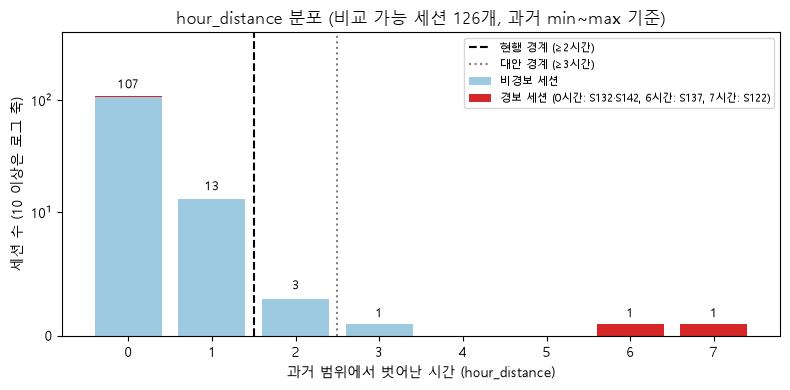

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
vals = np.arange(0, int(cmp["dist"].max()) + 1)
na = [int(((cmp["dist"] == v) & ~cmp["alert"]).sum()) for v in vals]
al = [int(((cmp["dist"] == v) & cmp["alert"]).sum()) for v in vals]
ax.bar(vals, na, color="#9ecae1", label="비경보 세션")
ax.bar(vals, al, bottom=na, color="#d62728", label="경보 세션 (0시간: S132·S142, 6시간: S137, 7시간: S122)")
for v, a, b in zip(vals, na, al):
    if a + b:
        ax.text(v, (a + b) * 1.12 + 0.2, str(a + b), ha="center", va="bottom", fontsize=9)
ax.axvline(1.5, color="black", linestyle="--", label="현행 경계 (≥2시간)")
ax.axvline(2.5, color="gray", linestyle=":", label="대안 경계 (≥3시간)")
ax.set_yscale("symlog", linthresh=10)
ax.set_ylim(0, 400)
ax.set_title(f"hour_distance 분포 (비교 가능 세션 {len(cmp)}개, 과거 min~max 기준)")
ax.set_xlabel("과거 범위에서 벗어난 시간 (hour_distance)")
ax.set_ylabel("세션 수 (10 이상은 로그 축)")
ax.set_xticks(vals)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**한 줄 결론** — 비경보/정상 후보 수는 방법에 따라 4 → 1 → 2개로 움직이지만, S122(7시간)와 S137(6시간)은 세 방법 모두에서 유지된다.

- B(3시간)로 올리면 2시간 이탈 3개(S050·S053·S063)가 빠지고 S026(3시간)만 남는다.
- C(분위수)는 과거 10개 이상인 75개 세션에서만 계산했다. S026·S063은 과거 6개라 `표본 부족`이다. 계산된 범위는 min~max와 거의 같다(예: S050은 9~15로 동일). 이 표본 크기에서는 분위수가 min~max를 실질적으로 대체하지 못한다.
- 자정 넘김: 시작 시각이 2~19시에만 있어 직선 거리와 원형 거리가 다른 세션은 0개다. 현재 데이터에서는 왜곡이 없다.
- 범위 오염: 과거 min~max는 한 번 들어온 이상 시각을 그대로 범위에 넣는다. S122 뒤 dev02의 범위는 3~18시, S137 뒤 ops02의 범위는 2~16시가 되어, 이후 같은 사람의 새벽 세션은 범위 안으로 계산된다(해당 5개 세션).

# 4. 기준선 최소 표본 3/5/7 비교

**현재 기준** — person 과거 ≥5 → 부족하면 peer ≥5 → global ≥5 → none.

**검증 방법** — 최소 세션 수만 3·5·7로 바꿔 `baseline_level`을 다시 계산한다 (과거 세션만 쓰는 조건 유지).
B01·B08은 세션 테이블만으로 다시 계산할 수 있어 함께 본다.
B01은 현행 임계값(2시간)과 B08 항목(process_count, non_get_count)을 고정한 값과, 5% 규칙을 다시 적용했을 때의 값을 모두 적는다.

**한계** — B02~B07·B09와 위험점수·경보는 다시 계산하지 않았다 (명령·IP 이력 등 전체 파이프라인이 필요). 여기서는 B01·B08 건수까지만 본다.

In [13]:
RARE = 0.05
tables = {n: baseline_table(n) for n in (3, 5, 7)}
rows, level_rows = [], []
for n_min, t in tables.items():
    c = t[t["level"].isin(["person", "peer"])]
    b01 = c[c["dist"] >= 2]
    b08 = c[c["process_count_above"] | c["non_get_count_above"]]
    share = {d: (c["dist"] >= d).mean() for d in range(1, int(c["dist"].max()) + 1)}
    d_rule = min(d for d, s in share.items() if s <= RARE)
    items = [k for k in ["process_count", "non_get_count"] if c[f"{k}_above"].mean() <= RARE]
    lv = t["level"].value_counts()
    level_rows.append({"최소 세션": n_min, **{k: int(lv.get(k, 0)) for k in ["person", "peer", "global", "none"]}})
    rows.append({
        "최소 세션": n_min, "비교 가능(person+peer)": len(c),
        "B01 건수 (2시간 고정)": len(b01), "B01 세션": " ".join(b01["work_session_id"]),
        "5% 규칙 재적용 시 B01 임계값(시간)": d_rule,
        "└ 그 임계값의 B01 세션": " ".join(c.loc[c["dist"] >= d_rule, "work_session_id"]),
        "B08 건수 (항목 고정)": len(b08), "B08 세션": " ".join(b08["work_session_id"]),
        "5% 규칙 통과 항목": ", ".join(items),
    })
level_tbl = pd.DataFrame(level_rows).set_index("최소 세션")
display(level_tbl)
display(pd.DataFrame(rows))

assert level_tbl.loc[5].to_dict() == sb["baseline_level"].value_counts().to_dict()
cur_b01 = set(det.loc[det.detection_type == "B01", "work_session_id"])
cur_b08 = set(det.loc[det.detection_type == "B08", "work_session_id"])
assert set(rows[1]["B01 세션"].split()) == cur_b01 and set(rows[1]["B08 세션"].split()) == cur_b08
print("최소 5세션 재계산 결과가 현행 detections.csv의 B01·B08과 일치")

,person,peer,global,none
최소 세션,,,,
3,122,12,9,3
5,106,20,15,5
7,90,28,19,9


,최소 세션,비교 가능(person+peer),B01 건수 (2시간 고정),B01 세션,5% 규칙 재적용 시 B01 임계값(시간),└ 그 임계값의 B01 세션,B08 건수 (항목 고정),B08 세션,5% 규칙 통과 항목
0,3,134,10,S018 S021 S026 S041 S043 S050 S053 S063 S122 S137,4,S041 S122 S137,7,S036 S043 S053 S131 S132 S139 S142,"process_count, non_get_count"
1,5,126,6,S026 S050 S053 S063 S122 S137,2,S026 S050 S053 S063 S122 S137,5,S036 S131 S132 S139 S142,"process_count, non_get_count"
2,7,118,4,S050 S053 S122 S137,2,S050 S053 S122 S137,4,S131 S132 S139 S142,"process_count, non_get_count"


최소 5세션 재계산 결과가 현행 detections.csv의 B01·B08과 일치


In [14]:
# 어느 세션의 기준선 수준이 달라지는가
lv = pd.DataFrame({n: t.set_index("work_session_id")["level"] for n, t in tables.items()})
order = {sid: i + 1 for i, sid in enumerate(ses["work_session_id"])}
diff_rows = []
for a in (3, 7):
    ch = lv[lv[a] != lv[5]]
    diff_rows.append({
        "비교": f"5 → {a}", "수준이 달라진 세션 수": len(ch), "전체 대비": f"{len(ch) / len(lv):.1%}",
        "가장 늦은 세션": ch.index.max(), "시작 순서 범위": f"{min(order[s] for s in ch.index)}~{max(order[s] for s in ch.index)} / {len(lv)}",
        "변화 유형": ", ".join(f"{x}→{y} {n}개" for (x, y), n in ch.groupby([5, a]).size().items()),
    })
display(pd.DataFrame(diff_rows))
watch = sorted(ALERT | cur_b01 | cur_b08)
w = lv.loc[watch].copy()
w.columns = [f"최소 {c}" for c in w.columns]
w["과거 세션 수(최소 5 기준)"] = tables[5].set_index("work_session_id").loc[watch, "n"]
w["구분"] = ["경보" if s in ALERT else "비경보/정상 후보" for s in watch]
display(w)

,비교,수준이 달라진 세션 수,전체 대비,가장 늦은 세션,시작 순서 범위,변화 유형
0,5 → 3,24,16.4%,S057,4~57 / 146,"global→peer 6개, global→person 2개, none→global 2개, peer→person 14개"
1,5 → 7,26,17.8%,S082,6~82 / 146,"global→none 4개, peer→global 6개, person→global 2개, person→peer 14개"


,최소 3,최소 5,최소 7,과거 세션 수(최소 5 기준),구분
work_session_id,,,,,
S026,person,person,global,6,비경보/정상 후보
S036,peer,peer,global,5,비경보/정상 후보
S050,person,peer,peer,14,비경보/정상 후보
S053,person,peer,peer,10,비경보/정상 후보
S063,person,person,peer,6,비경보/정상 후보
S122,person,person,person,13,경보
S131,person,person,person,27,비경보/정상 후보
S132,person,person,person,10,경보
S137,person,person,person,15,경보


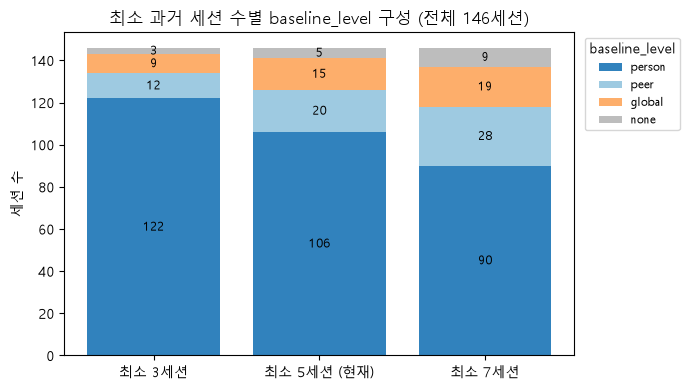

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
bottom = np.zeros(len(level_tbl))
colors = {"person": "#3182bd", "peer": "#9ecae1", "global": "#fdae6b", "none": "#bdbdbd"}
x = np.arange(len(level_tbl))
for k in ["person", "peer", "global", "none"]:
    ax.bar(x, level_tbl[k], bottom=bottom, color=colors[k], label=k)
    for i, v in enumerate(level_tbl[k]):
        if v:
            ax.text(i, bottom[i] + v / 2, str(v), ha="center", va="center", fontsize=9)
    bottom += level_tbl[k].to_numpy()
ax.set_xticks(x)
ax.set_xticklabels([f"최소 {n}세션" + (" (현재)" if n == 5 else "") for n in level_tbl.index])
ax.set_ylabel("세션 수")
ax.set_title("최소 과거 세션 수별 baseline_level 구성 (전체 146세션)")
ax.legend(title="baseline_level", fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

**한 줄 결론** — 최소 세션 수를 바꾸면 person 비중이 122 / 106 / 90개로 움직이지만 차이는 앞쪽 세션(3은 57번째, 7은 82번째까지)에만 있고, 경보 4개 세션은 세 값 모두 person 기준선이다.

- 수준이 달라지는 세션은 5→3에서 24개(16.4%), 5→7에서 26개(17.8%)다.
- B01은 10 / 6 / 4건, B08은 7 / 5 / 4건이다. 달라지는 것은 모두 비경보/정상 후보이고, S122·S137의 B01과 S132·S142의 B08은 세 값 모두에서 유지된다.
- 최소 3에서는 2시간 이탈 비율이 5%를 넘어, 5% 규칙을 다시 적용하면 B01 임계값이 4시간으로 올라간다(그때 B01은 S041·S122·S137). 임계값 자체도 이 값의 영향을 받는다.
- 한계: B02~B07·B09와 위험점수는 다시 계산하지 않았다.

# 5. B08 행동량 정규화 비교

**현재 기준** — `process_count`(또는 `non_get_count`)가 과거 최대를 넘으면 B08. raw count를 그대로 비교한다.

**검증 방법** — B08 로직을 바꾸는 것이 아니라 "raw count가 병합 세션에 불리한가"를 진단한다.

- A. raw `process_count`
- B. 접속 수 보정 `process_count / ssh_connections` (접속 수 0이면 계산하지 않음)
- C. 시간 보정 `process_count / (duration_min / 60)` (5분 미만 세션은 값이 튀므로 계산하지 않고 따로 표시)

세 값 모두 현행과 같은 과거 세션(최소 5, 과거만)에 대해 "과거 최대 초과" 여부를 본다.

In [16]:
SHORT_MIN = 5
v = ses[["work_session_id", "person_candidate", "ssh_connections", "duration_min", "process_count", "non_get_count"]].copy()
v["per_conn"] = np.where(v["ssh_connections"] > 0, v["process_count"] / v["ssh_connections"].replace(0, np.nan), np.nan)
v["short"] = v["duration_min"] < SHORT_MIN
v["per_hour"] = np.where(~v["short"], v["process_count"] / (v["duration_min"] / 60), np.nan)
v["병합"] = np.select([v["ssh_connections"] == 0, v["ssh_connections"] == 1], ["SSH 없음", "1접속"], "2접속 이상 병합")
print("ssh_connections = 0 (접속 수 보정 제외):", v.loc[v.ssh_connections == 0, "work_session_id"].tolist())
print(f"{SHORT_MIN}분 미만 (시간 보정 제외):", v.loc[v.short, ["work_session_id", "duration_min"]].values.tolist())

dist_tbl = v[v["병합"] != "SSH 없음"].groupby("병합")[["process_count", "per_conn", "per_hour"]].agg(["count", "median", "max"]).round(1)
dist_tbl.columns = [f"{ {'process_count': 'raw', 'per_conn': '접속당', 'per_hour': '시간당'}[a] } {b}" for a, b in dist_tbl.columns]
display(dist_tbl)
display(v[v["병합"] == "2접속 이상 병합"][["work_session_id", "person_candidate", "ssh_connections", "duration_min",
                                        "process_count", "per_conn", "per_hour"]].round(1).reset_index(drop=True))

ssh_connections = 0 (접속 수 보정 제외): ['S132']
5분 미만 (시간 보정 제외): [['S002', 3.6], ['S022', 4.6], ['S038', 4.8], ['S116', 3.1], ['S132', 1.2]]


,raw count,raw median,raw max,접속당 count,접속당 median,접속당 max,시간당 count,시간당 median,시간당 max
병합,,,,,,,,,
1접속,142,3.0,4,142,3.0,4.0,138,7.9,44.4
2접속 이상 병합,3,7.0,10,3,2.3,3.3,3,10.5,12.7


,work_session_id,person_candidate,ssh_connections,duration_min,process_count,per_conn,per_hour
0,S131,ops01,3,49.3,7,2.3,8.5
1,S139,ops01,3,57.1,10,3.3,10.5
2,S142,intern01,2,18.9,4,2.0,12.7


In [17]:
vi = v.set_index("work_session_id")
rows = []
for x in ses.itertuples():
    level, H = history(x, 5)
    if level not in ("person", "peer"):
        continue
    hv, me = vi.loc[H["work_session_id"]], vi.loc[x.work_session_id]
    r = {"work_session_id": x.work_session_id, "person": x.person_candidate, "level": level, "n": len(H),
         "ssh_connections": me.ssh_connections, "duration_min": me.duration_min}
    for col, lab in [("process_count", "raw"), ("per_conn", "접속당"), ("per_hour", "시간당")]:
        r[lab] = me[col]
        r[f"{lab} 과거 최대"] = hv[col].max()
        r[f"{lab} 초과"] = bool(me[col] > hv[col].max()) if pd.notna(me[col]) and hv[col].notna().any() else None
        r[f"{lab} 전체 순위"] = int((vi[col] > me[col]).sum()) + 1 if pd.notna(me[col]) else None
    rows.append(r)
vol = pd.DataFrame(rows)
vol["alert"] = vol["work_session_id"].isin(ALERT)
assert set(vol.loc[vol["raw 초과"] == True, "work_session_id"]) == set(sb.loc[sb.process_count_above_max.astype(str).str.lower().eq("true") & sb.baseline_level.isin(["person", "peer"]), "work_session_id"])

FOCUS = ["S036", "S131", "S139"]
focus = vol.set_index("work_session_id").loc[FOCUS, ["person", "level", "n", "ssh_connections", "duration_min",
                                                      "raw", "raw 과거 최대", "raw 초과", "raw 전체 순위",
                                                      "접속당", "접속당 과거 최대", "접속당 초과", "접속당 전체 순위",
                                                      "시간당", "시간당 과거 최대", "시간당 초과", "시간당 전체 순위"]].round(1)
display(focus.T)

sum_rows = []
for lab in ["raw", "접속당", "시간당"]:
    ok = vol[f"{lab} 초과"].notna()
    hit = vol[vol[f"{lab} 초과"] == True]
    sum_rows.append({
        "비교값": {"raw": "A. raw process_count", "접속당": "B. 접속 수 보정", "시간당": "C. 시간 보정"}[lab],
        "계산 가능 세션": int(ok.sum()), "과거 최대 초과 세션 수": len(hit), "초과 비율": f"{len(hit) / ok.sum():.1%}",
        "초과 세션": " ".join(hit["work_session_id"]),
        "그중 비경보/정상 후보 수": int((~hit["alert"]).sum()),
        "S036": "초과" if "S036" in set(hit.work_session_id) else "-",
        "S131": "초과" if "S131" in set(hit.work_session_id) else "-",
        "S139": "초과" if "S139" in set(hit.work_session_id) else "-",
    })
b08_tbl = pd.DataFrame(sum_rows)
display(b08_tbl)

# 기존 의심(경보) 세션의 B08 신호는 어느 항목에서 나왔나
b08_alert = det[(det.detection_type == "B08") & det.work_session_id.isin(ALERT)][["work_session_id", "evidence"]]
b08_alert = b08_alert.merge(vol[["work_session_id", "raw", "raw 초과", "접속당 초과", "시간당 초과"]], on="work_session_id", how="left")
display(b08_alert)

work_session_id,S036,S131,S139
person,web01,ops01,ops01
level,peer,person,person
n,5,27,28
ssh_connections,1,3,3
duration_min,35.1,49.3,57.1
raw,4,7,10
raw 과거 최대,3,4,7
raw 초과,True,True,True
raw 전체 순위,3,2,1
접속당,4.0,2.3,3.3


,비교값,계산 가능 세션,과거 최대 초과 세션 수,초과 비율,초과 세션,그중 비경보/정상 후보 수,S036,S131,S139
0,A. raw process_count,126,3,2.4%,S036 S131 S139,3,초과,초과,초과
1,B. 접속 수 보정,125,1,0.8%,S036,1,초과,-,-
2,C. 시간 보정,122,12,9.8%,S029 S048 S050 S053 S058 S064 S069 S071 S074 S091 S124 S145,12,-,-,-


,work_session_id,evidence,raw,raw 초과,접속당 초과,시간당 초과
0,S132,[person n=10] 과거 최대 초과: non_get_count=9,0,False,None,None
1,S142,[person n=11] 과거 최대 초과: non_get_count=4,4,False,False,False


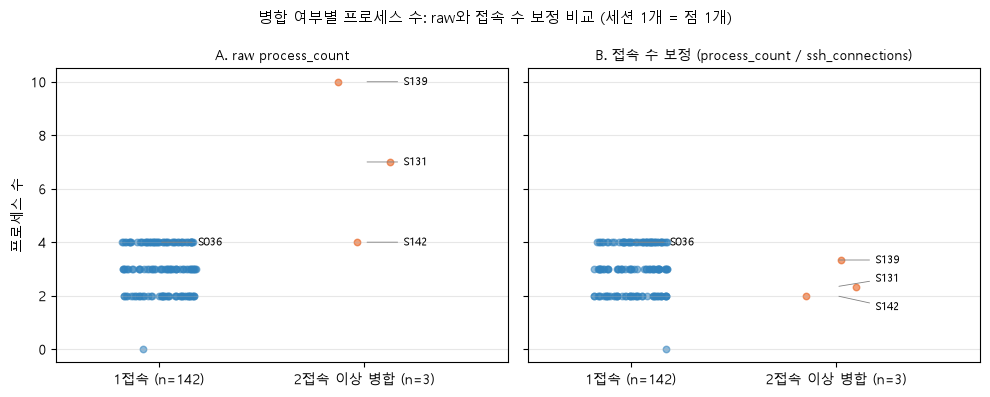

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
rng = np.random.default_rng(0)
pv = v[v["병합"] != "SSH 없음"]
for ax, col, title in [(axes[0], "process_count", "A. raw process_count"), (axes[1], "per_conn", "B. 접속 수 보정 (process_count / ssh_connections)")]:
    for i, grp in enumerate(["1접속", "2접속 이상 병합"]):
        g = pv[pv["병합"] == grp]
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(g)), g[col], s=22, alpha=0.55, color="#3182bd" if i == 0 else "#e6550d")
        for r in g[g["work_session_id"].isin(FOCUS + ["S142"])].itertuples():
            dy = {"S131": 6, "S142": -8}.get(r.work_session_id, 0) if col == "per_conn" else 0
            ax.annotate(r.work_session_id, (i, getattr(r, col)), xytext=(28, dy), textcoords="offset points", fontsize=8,
                        va="center", arrowprops={"arrowstyle": "-", "color": "gray", "lw": 0.6})
    ax.set_xticks([0, 1])
    ax.set_xticklabels([f"1접속 (n={int((pv['병합'] == '1접속').sum())})", f"2접속 이상 병합 (n={int((pv['병합'] == '2접속 이상 병합').sum())})"])
    ax.set_xlim(-0.5, 1.7)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("프로세스 수")
fig.suptitle("병합 여부별 프로세스 수: raw와 접속 수 보정 비교 (세션 1개 = 점 1개)", fontsize=11)
plt.tight_layout()
plt.show()

**한 줄 결론** — raw `process_count`는 병합 세션에 불리하다. S131·S139는 접속 수로 나누면 과거 최대 아래로 내려가지만, S036은 1접속 세션이라 병합으로 설명되지 않는다.

- S131·S139(각 3접속)는 raw로 전체 2위·1위지만 접속당 2.3·3.3으로 1접속 세션의 통상 범위(중앙값 3, 최대 4) 안이다.
- S036은 1접속에 프로세스 4개로, 접속 수 보정 뒤에도 초과다(과거 최대 3). 원인은 병합이 아니라 peer 과거 5개라는 작은 표본 쪽이다(4번에서 최소 7이면 사라짐).
- 시간 보정은 세 세션을 모두 내리지만 새로 12개 세션(9.8%)이 과거 최대를 넘는다. 짧은 세션에서 값이 튀어 잡음이 더 크다.
- 경보 세션 S132·S142의 B08은 `non_get_count`에서 나온 것이라 이 보정과 무관하게 유지된다. `process_count`로 걸린 B08 3건은 모두 비경보/정상 후보다.
- 병합 세션은 3개뿐이라 일반화하기 어렵다.

# 6. 최종 요약

In [19]:
summary = pd.DataFrame([['1. 시스템 탐지 → 사용자 귀속', '같은 서버(hosts 또는 home_host)·SSH 시간 안', 'S137 연결 12건 모두 후보 1명. 그러나 node-01 접속은 home_host 추정이고 auditd·sudo·node-01 로그인 기록이 없음. 연결 제외 시 40점', '⚪ 현재 데이터로 확인 불가'], ['2. R09 SSH 실패 반복', '같은 IP, 1시간 안 5회 이상', '현행 0개 IP. 24시간/5회·7일/5회·7일/10회에서 외부 시도 IP 3개 모두 탐지. 내부 IP 추가 0 (단, 내부 IP 실패 자체가 0건)', '🔴 보완 검토 필요'], ['3. B01 시작 시각', '과거 min~max에서 2시간 이상 이탈', '비경보/정상 후보 4 → 1(3시간) → 2(분위수, 75개만 계산). S122·S137은 모두 유지', '🟡 영향은 있으나 현재 결과 유지'], ['4. 기준선 최소 과거 세션', 'person/peer/global 각 5세션 이상', 'person 122 / 106 / 90. 변화는 앞쪽 57~82번째 세션까지. B01 10/6/4건, B08 7/5/4건. 경보 4개 세션은 모두 person', '🟡 영향은 있으나 현재 결과 유지'], ['5. B08 병합 세션 행동량', 'raw process_count가 과거 최대 초과', 'S131·S139는 접속 수 보정 시 초과 해소, S036은 유지(1접속, peer n=5). 시간 보정은 새 초과 12개. 경보 세션 B08은 non_get_count라 무관', '🟡 영향은 있으나 현재 결과 유지']], columns=["항목", "현재 기준", "검증 결과", "판단"])
with pd.option_context("display.max_colwidth", None):
    display(summary)

,항목,현재 기준,검증 결과,판단
0,1. 시스템 탐지 → 사용자 귀속,같은 서버(hosts 또는 home_host)·SSH 시간 안,S137 연결 12건 모두 후보 1명. 그러나 node-01 접속은 home_host 추정이고 auditd·sudo·node-01 로그인 기록이 없음. 연결 제외 시 40점,⚪ 현재 데이터로 확인 불가
1,2. R09 SSH 실패 반복,"같은 IP, 1시간 안 5회 이상","현행 0개 IP. 24시간/5회·7일/5회·7일/10회에서 외부 시도 IP 3개 모두 탐지. 내부 IP 추가 0 (단, 내부 IP 실패 자체가 0건)",🔴 보완 검토 필요
2,3. B01 시작 시각,과거 min~max에서 2시간 이상 이탈,"비경보/정상 후보 4 → 1(3시간) → 2(분위수, 75개만 계산). S122·S137은 모두 유지",🟡 영향은 있으나 현재 결과 유지
3,4. 기준선 최소 과거 세션,person/peer/global 각 5세션 이상,"person 122 / 106 / 90. 변화는 앞쪽 57~82번째 세션까지. B01 10/6/4건, B08 7/5/4건. 경보 4개 세션은 모두 person",🟡 영향은 있으나 현재 결과 유지
4,5. B08 병합 세션 행동량,raw process_count가 과거 최대 초과,"S131·S139는 접속 수 보정 시 초과 해소, S036은 유지(1접속, peer n=5). 시간 보정은 새 초과 12개. 경보 세션 B08은 non_get_count라 무관",🟡 영향은 있으나 현재 결과 유지


- 판단 기호: ✅ 현재 기준 유지 가능 / 🟡 영향은 있으나 현재 결과 유지 / 🔴 보완 검토 필요 / ⚪ 현재 데이터로 확인 불가
- "현재 결과 유지"는 **이 데이터에서** 경보 4개와 그 세션의 해당 신호가 유지된다는 뜻이다. 일반적으로 적절한 값이라는 뜻이 아니다.
- 3·4·5번에서 움직인 것은 모두 비경보/정상 후보(행위 신호 1개, 20점)다. 위험점수와 경보는 이 notebook에서 다시 계산하지 않았다.